In [ ]:
import os
import sys

sys.path.append("../utils")
from data_loader import load_bill_data

from embedding_utils import extract_embeddings
from transformers import AutoTokenizer, AutoModel
from embedding_utils import extract_embeddings

import pandas as pd
import numpy as np

from scipy.stats import normaltest, kstest, anderson
import matplotlib.pyplot as plt
import seaborn as sns

# Finding potential outliers

In [138]:
fields_to_extract = {
    "bill_number": "bill_data.number",
    "bill_url": "bill_data.url",
    "bill_title": "bill_data.title",
    "sponsor_name": "sponsor.name",
    "sponsor_url": "sponsor.url",
    "summary_title": "summary.title",
    "summary_text": "summary.text",
    "source_url": "metadata.source_url",
    "view_text_url": "view_text_url",
    "is_home_rule": "is_home_rule",
    "municipality": "municipality",
    "num_cosponsors": "num_cosponsors",
    "cosponsors": "cosponsors",  
    "history": "history"
}


root_path ='../../downloaded_legislation/'
json_files = os.path.join(root_path, 'state/MA/*/*/*/*/*.json') # glob pattern for json files

df = load_bill_data(json_files, fields_to_extract)
df.head()

,bill_number,bill_url,bill_title,sponsor_name,sponsor_url,summary_title,summary_text,source_url,view_text_url,is_home_rule,municipality,num_cosponsors,cosponsors,history
0,H.4147,https://malegislature.gov/Bills/192/H4147,An Act providing technical education and econo...,"Harrington, Sheila C.",https://malegislature.gov/Legislators/Profile/...,An Act providing technical education and econo...,"(a) For purposes of this act, “autism spectrum...",https://malegislature.gov/Bills/192/H4147,https://malegislature.gov/Bills/192/H4147/Hous...,False,None,3,"[{'name': 'Lindsay N. Sabadosa', 'district': '...","[{'date': '9/30/2021', 'branch': 'House', 'act..."
1,S.1263,https://malegislature.gov/Bills/192/S1263,An Act relative to recovery homes,"Collins, Nick",https://malegislature.gov/Legislators/Profile/...,An Act relative to recovery homes,Nothwithstanding any special or general law to...,https://malegislature.gov/Bills/192/S1263,https://malegislature.gov/Bills/192/S1263/Sena...,False,None,0,[],"[{'date': '3/29/2021', 'branch': 'Senate', 'ac..."
2,H.3682,https://malegislature.gov/Bills/192/H3682,An Act amending the Medal of Liberty,"Murray, Brian W.",https://malegislature.gov/Legislators/Profile/...,An Act amending the Medal of Liberty,"Chapter 33 Section 67A of the General Laws, as...",https://malegislature.gov/Bills/192/H3682,https://malegislature.gov/Bills/192/H3682/Hous...,False,None,7,"[{'name': 'Michael J. Soter', 'district': '8th...","[{'date': '3/29/2021', 'branch': 'House', 'act..."
3,SD.3464,https://malegislature.gov/Bills/192/SD3464,DVS Veteran Advisory Committee Interim Report,None,None,DVS Veteran Advisory Committee Interim Report,Report of the Department of Veterans’ Services...,https://malegislature.gov/Bills/192/SD3464,None,False,None,0,[],"[{'date': '1/3/2023', 'branch': 'Senate', 'act..."
4,H.2990,https://malegislature.gov/Bills/192/H2990,An Act to encourage Massachusetts residency,"Livingstone, Jay D.",https://malegislature.gov/Legislators/Profile/...,An Act to encourage Massachusetts residency,SECTION 1. Chapter 65C of the General Laws is ...,https://malegislature.gov/Bills/192/H2990,https://malegislature.gov/Bills/192/H2990/Hous...,False,None,1,"[{'name': 'Carlos González', 'district': '10th...","[{'date': '3/29/2021', 'branch': 'House', 'act..."


In [139]:
df['history_data_length'] = df.history.apply(lambda x: len(x) if isinstance(x, list) else 0)

In [140]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70641 entries, 0 to 70640
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   bill_number          70641 non-null  object
 1   bill_url             70641 non-null  object
 2   bill_title           70641 non-null  object
 3   sponsor_name         47629 non-null  object
 4   sponsor_url          45806 non-null  object
 5   summary_title        70641 non-null  object
 6   summary_text         70641 non-null  object
 7   source_url           70641 non-null  object
 8   view_text_url        63308 non-null  object
 9   is_home_rule         70641 non-null  bool  
 10  municipality         3995 non-null   object
 11  num_cosponsors       70641 non-null  int64 
 12  cosponsors           70641 non-null  object
 13  history              70331 non-null  object
 14  history_data_length  70641 non-null  int64 
dtypes: bool(1), int64(2), object(12)
memory usage: 7.6+ M

### Numeric data

In [ ]:
def check_normality(series):
    """
    Check normality of a data series.
    """
    series = series.dropna()  

    # D’Agostino’s K-squared Test
    normaltest_result = normaltest(series)
    print(f"D’Agostino’s K-squared Test: Statistic = {normaltest_result.statistic:.4f}, p-value = {normaltest_result.pvalue:.4f}")
    
    # Kolmogorov-Smirnov Test (Compares distribution with a standard normal distribution)
    ks_result = kstest((series - series.mean()) / series.std(), 'norm')
    print(f"Kolmogorov-Smirnov Test: Statistic = {ks_result.statistic:.4f}, p-value = {ks_result.pvalue:.4f}")
    
    # Anderson-Darling Test (Gives critical values instead of p-value)
    anderson_result = anderson(series)
    print(f"Anderson-Darling Test: Statistic = {anderson_result.statistic:.4f}")
    for i, (cv, sig_level) in enumerate(zip(anderson_result.critical_values, anderson_result.significance_level)):
        print(f"  Significance level: {sig_level}% | Critical value: {cv}")
    
    if normaltest_result.pvalue < 0.05 or ks_result.pvalue < 0.05:
        print("\n❌ Data is likely NOT normally distributed.")
    else:
        print("\n✅ Data is likely normally distributed.")


for field in ['history_data_length', 'num_cosponsors']:
    check_normality(df[field])
    print()

D’Agostino’s K-squared Test: Statistic = 27249.2807, p-value = 0.0000
Kolmogorov-Smirnov Test: Statistic = 0.2428, p-value = 0.0000
Anderson-Darling Test: Statistic = 4848.9088
  Significance level: 15.0% | Critical value: 0.576
  Significance level: 10.0% | Critical value: 0.656
  Significance level: 5.0% | Critical value: 0.787
  Significance level: 2.5% | Critical value: 0.918
  Significance level: 1.0% | Critical value: 1.092

❌ Data is likely NOT normally distributed.

D’Agostino’s K-squared Test: Statistic = 70342.8725, p-value = 0.0000
Kolmogorov-Smirnov Test: Statistic = 0.3420, p-value = 0.0000
Anderson-Darling Test: Statistic = 12845.4496
  Significance level: 15.0% | Critical value: 0.576
  Significance level: 10.0% | Critical value: 0.656
  Significance level: 5.0% | Critical value: 0.787
  Significance level: 2.5% | Critical value: 0.918
  Significance level: 1.0% | Critical value: 1.092

❌ Data is likely NOT normally distributed.



Since columns are not normally distributed, we will use the IQR. 

Outliers in history_data_length:
9709


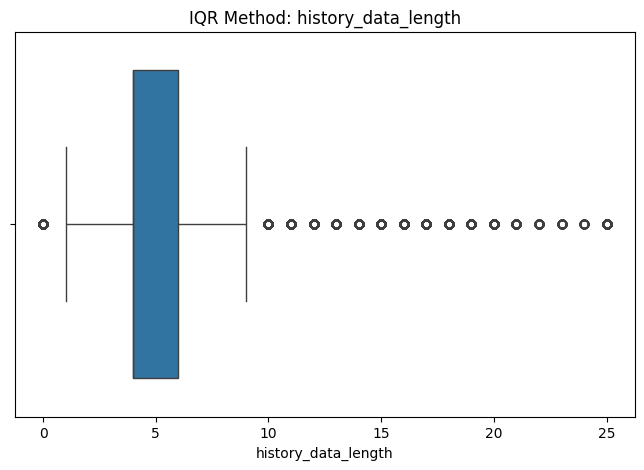

Outliers in num_cosponsors:
10520


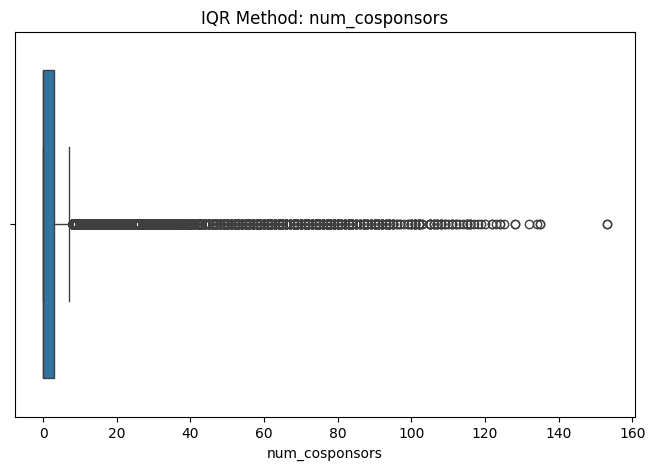

In [142]:
def detect_outliers_iqr(series: pd.Series, multiplier: float = 1.5) -> pd.Series:
    """
    Detects outliers in a pandas Series using the IQR method.
    
    Args:
        series (pd.Series): The numeric Series to analyze.
        multiplier (float): The IQR multiplier to flag outliers (default: 1.5).
    
    Returns:
        pd.Series: A boolean Series where True indicates an outlier.
    """
    # Calculate Q1, Q3, and IQR
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds
    lower_bound = Q1 - multiplier * IQR
    upper_bound = Q3 + multiplier * IQR
    
    # Return boolean series indicating which entries are outliers
    return (series < lower_bound) | (series > upper_bound)


def plot_boxplot_with_outliers(series: pd.Series, title: str = "Box Plot with IQR Outliers"):
    """
    Displays a box plot with outliers highlighted based on IQR.
    """
    plt.figure(figsize=(8, 5))
    sns.boxplot(x=series)
    plt.title(title)
    plt.xlabel(series.name)
    plt.show()

for field in ['history_data_length', 'num_cosponsors']:
    print(f"Outliers in {field}:")
    df[f'{field}_outliers'] = detect_outliers_iqr(df[field])
    print(sum(df[f'{field}_outliers']) )
    plot_boxplot_with_outliers(df[field], title=f"IQR Method: {field}")


In [149]:
df[df.history_data_length==25].iloc[0].history

[{'date': '7/8/2021',
  'branch': 'House',
  'action': 'Reported from the committee of conference'},
 {'date': '7/8/2021',
  'branch': 'House',
  'action': 'Reported on a part of H4001'},
 {'date': '7/8/2021',
  'branch': 'House',
  'action': 'Referred to the committee on House Steering, Policy and Scheduling'},
 {'date': '7/8/2021',
  'branch': 'House',
  'action': 'Committee reported that the matter be placed in the Orders of the Day for the next sitting, the question being on acceptance'},
 {'date': '7/9/2021', 'branch': 'House', 'action': 'Rules suspended'},
 {'date': '7/9/2021',
  'branch': 'House',
  'action': 'Committee of conference report accepted - 160 YEAS to 0 NAYS (See YEA and NAY No. 66 )'},
 {'date': '7/9/2021', 'branch': 'Senate', 'action': 'Rules suspended'},
 {'date': '7/9/2021',
  'branch': 'Senate',
  'action': 'Committee of conference report accepted, in concurrence -see   Roll Call #54 (Yeas 40 to Nays 0)'},
 {'date': '7/9/2021',
  'branch': 'House',
  'action': '

In [150]:
df[df.num_cosponsors>100].iloc[0].history

[{'date': '3/29/2021',
  'branch': 'House',
  'action': 'Referred to the committee on Labor and Workforce Development'},
 {'date': '3/29/2021', 'branch': 'Senate', 'action': 'Senate concurred'},
 {'date': '5/25/2021',
  'branch': 'Joint',
  'action': 'Hearing scheduled for 06/08/2021 from 10:30 AM-02:30 PM in Virtual Hearing'},
 {'date': '2/7/2022',
  'branch': 'House',
  'action': 'Reporting date extended to Monday April 4, 2022, pending concurrence'},
 {'date': '3/17/2022', 'branch': 'Senate', 'action': 'Senate concurred'},
 {'date': '4/11/2022',
  'branch': 'House',
  'action': 'Accompanied a new draft, see H4681'}]

### Boolean data

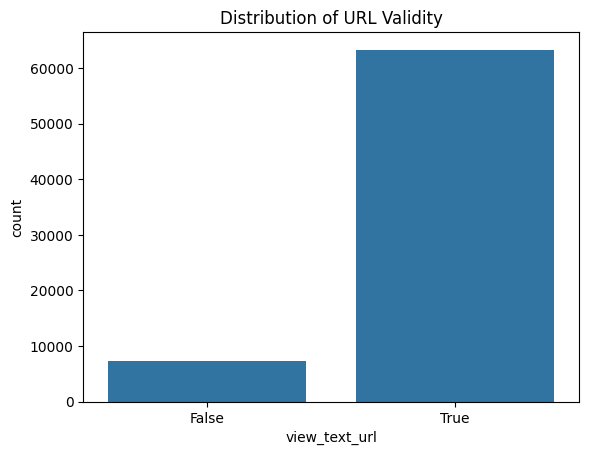

In [ ]:
valid_url =  df.view_text_url.apply(lambda x: False if x is  None or x == "" else True)
sns.countplot(x=valid_url)
plt.title("Distribution of URL Validity")
plt.show()

True count: 3203
False count: 67438


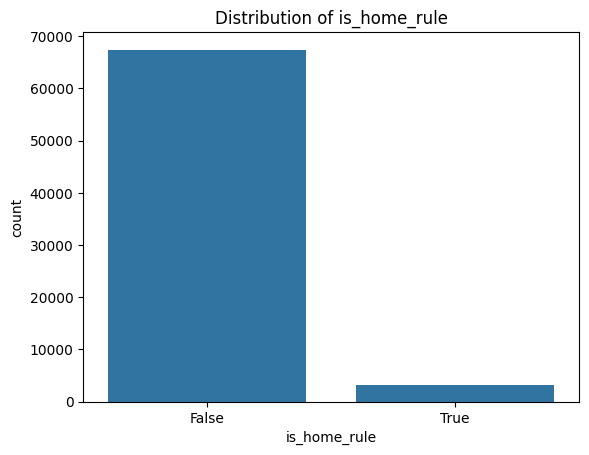

In [51]:
# Count True/False values
is_home_rule_counts = df['is_home_rule'].value_counts()
print("True count:", is_home_rule_counts.get(True, 0))
print("False count:", is_home_rule_counts.get(False, 0))

# Plotting distribution
sns.countplot(x=df['is_home_rule'])
plt.title("Distribution of is_home_rule")
plt.show()